In [2]:
import sys
RE_path = './RE_Solver/'
sys.path.insert(1, RE_path)

In [3]:
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
import importlib
import RE 
importlib.reload(RE)
from RE import *
from unit_conversion import *

# Deflection and Slowing Down Frequencies

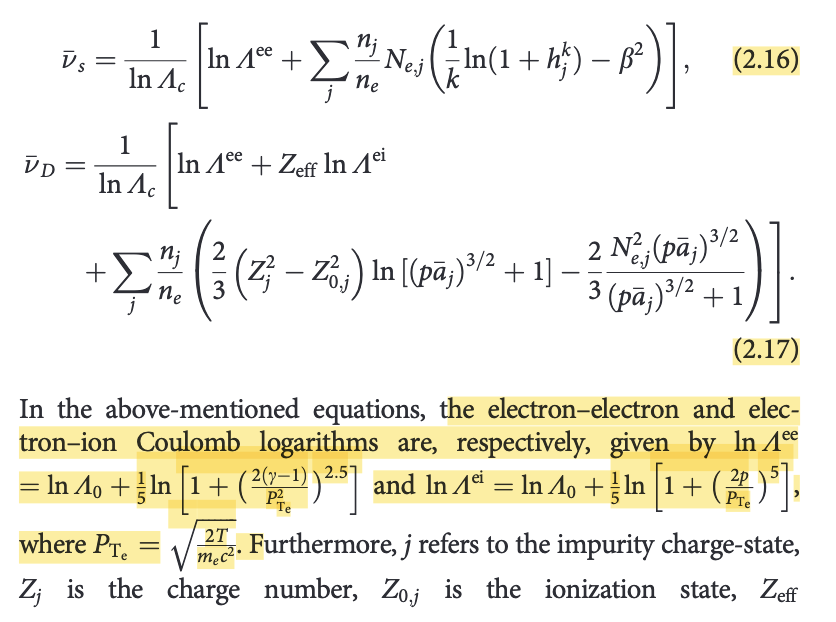

In [4]:
# functions

def get_nuD_nuS(p,Z,Z0,nj,T,element='Ne'): # default Ne
    
    # p = normalized momentum
    # Z = max. ionization
    # Z0 = ionization level
    # nj = density [per cubic m]
    # T = temperature [eV]
    # element = 'Ne' or 'Ar'
    
    # Constants
    if element == 'Ne':
        ln_aBar = np.array([4.7064, 4.6097, 4.5028, 4.3858, 4.2638, 4.1266, 3.9568, 3.6810, 3.1777, 3.1278])
        ln_I    = np.array([-8.2227, -8.0370, -7.8614, -7.6837, -7.4994, -7.2788, -6.9808, -6.5976, -5.8933, -5.8320])
    elif element == 'Ar':
        ln_aBar = np.array([4.5677, 4.5007, 4.4289, 4.3513, 4.2698, 4.1815, 4.0829, 3.9748,
                            3.8511, 3.7882, 3.7203, 3.6436, 3.5579, 3.4525, 3.3093, 3.0503, 2.5578, 2.5332])
        ln_I    = np.array([-7.9050, -7.7532, -7.6076, -7.4626, -7.3178, -7.1665, -7.0055, -6.8020,
                            -6.5538, -6.4647, -6.3644, -6.2465, -6.1070, -5.9219, -5.6535, -5.3213, -4.6937, -4.6598])
    else:
        raise ValueError("element must be 'Ne' or 'Ar'")
    
    
    aBar_Ne = np.exp(ln_aBar)
    I_Ne = np.exp(ln_I)
    k = 5
    
    # Other Quantities
    ne_free = np.sum(Z0 * nj) # Free electron density, per cubic m 
    Zeff = np.sum((Z0**2 * nj))/ne_free # Effective Ionization
    Ne = Z - Z0 # No. of bound electrons

    # Everything is a function of momentum p
    gamma = np.sqrt(1+p**2)
    beta = p**2 / (1 + p**2)
    
    # Coulomb Logs (also functions of p)
    PT = np.sqrt(2 * T / const.m_e / const.c**2) # Thermal velocity
    lnAc = 14.6 + 0.5 * np.log(T / (ne_free/1e20)) # RE-Thermal Coul. log
    lnA0 = 14.9 - 0.5 * np.log(ne_free/1e20) + np.log(T/1e3) # Thermal-Thermal Coul. Log
    lnAee = lnA0 + 1/5 * np.log(1 + (2*(gamma-1)/PT**2)**2.5)
    lnAei = lnA0 + 1/5 * np.log(1 + (2*p/PT)**5)
    # lnAee = lnAc + np.log(np.sqrt(gamma-1))
    # lnAei = lnAc + np.log(np.sqrt(2) * p)
    
    # Caluclate nuS and nuD (Bandaru + 2024)

    nuS = lnAee
    nuD = lnAee + Zeff * lnAei
    for j in range(1,Z.shape[0]):
        hj = p * np.sqrt(gamma-1) / I_Ne[Z0[j]]
        F1j = 1/k * np.log(1+hj**k) - beta**2
        pabar1p5 = (p*aBar_Ne[Z0[j]])**1.5
        nuS = nuS + (nj[j] / ne_free)  * Ne[j] * F1j
        nuD = nuD + (nj[j] / ne_free) * ( 
                      (2/3 * (Z[j]**2 - Z0[j]**2)) * np.log(pabar1p5+1)
                    - (2/3 * Ne[j]**2 * pabar1p5 / (pabar1p5+1))
                    )
#     # Hesslow + 2018    
#     nuS = lnAee
#     nuD = lnAee + Zeff * lnAei
#     for j in range(1,Z.shape[0]):
#         hj = p * np.sqrt(gamma-1) / I_Ne[Z0[j]]
#         nuS = nuS + (nj[j] / ne_free)  * Ne[j] * (np.log(hj) - beta**2)
#         nuD = nuD + (nj[j] / ne_free) * ( 
#                       (Z[j]**2 - Z0[j]**2) * np.log(p*aBar_Ne[Z0[j]])
#                     - 2/3 * Ne[j]**2
#                     )
        
    nuS = nuS / lnAc
    nuD = nuD / lnAc
    
    return nuD, nuS

##########

# Add the function for Argon
    

In [5]:
# Inputs
p_Ne = np.logspace(-1,2,1000)
Z_Ne = np.array([1,10]); # Max. Ionization
Z0_Ne = np.array([1,1]); # Ionization Level
nj_Ne = np.array([0,1e20]); # Density
T_Ne = 10;

nuD_Ne, nuS_Ne = get_nuD_nuS(p_Ne,Z_Ne,Z0_Ne,nj_Ne,T_Ne,element='Ne')

p_Ar = np.logspace(-1,2,1000)
Z_Ar = np.array([1,18]); # Max. Ionization
Z0_Ar = np.array([1,1]); # Ionization Level
nj_Ar = np.array([0,1e20]); # Density
T_Ar = 10;

nuD_Ar, nuS_Ar = get_nuD_nuS(p_Ar,Z_Ar,Z0_Ar,nj_Ar,T_Ar,element='Ar')

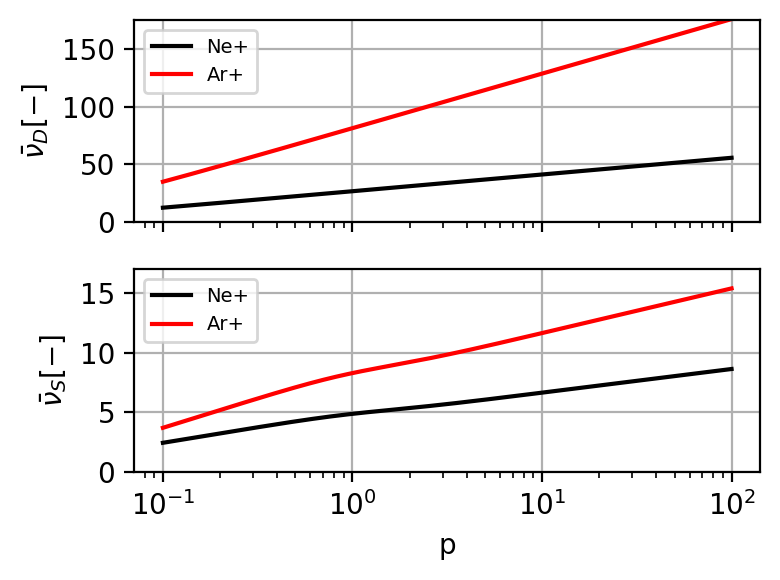

In [6]:
fig, axs = plt.subplots(2,1,dpi=200,sharex=True,figsize=(4,3))


axs[0].plot(p_Ne,nuD_Ne, color='k', label='Ne+')
axs[1].plot(p_Ne,nuS_Ne, color='k', label='Ne+')
axs[0].plot(p_Ar,nuD_Ar, color='r', label='Ar+')
axs[1].plot(p_Ar,nuS_Ar, color='r', label='Ar+')

axs[0].set_ylabel('$\\bar{\\nu}_D [-]$')
axs[1].set_ylabel('$\\bar{\\nu}_S [-]$')

for ax in axs:
    ax.grid()
    ax.set_xscale('log')
    ax.legend(fontsize=7, loc='upper left')
    
axs[-1].set_xlabel('p') 
axs[0].set_ylim([0,175])
axs[0].set_yticks([0,50,100,150])
axs[1].set_ylim([0,17])
axs[1].set_yticks([0, 5, 10, 15])

#plt.legend(fontsize=7, loc='upper left')
plt.tight_layout()

# Compare (Hesslow + 2018 Fig. 1)

# data = np.loadtxt(RE_path + '/data/HesslowNenuD.csv',delimiter=',')
# axs[0].plot(data[:,0],data[:,1],'rx')

# data = np.loadtxt(RE_path + '/data/HesslowNenuS.csv',delimiter=',')
# axs[1].plot(data[:,0],data[:,1],'rx')
    

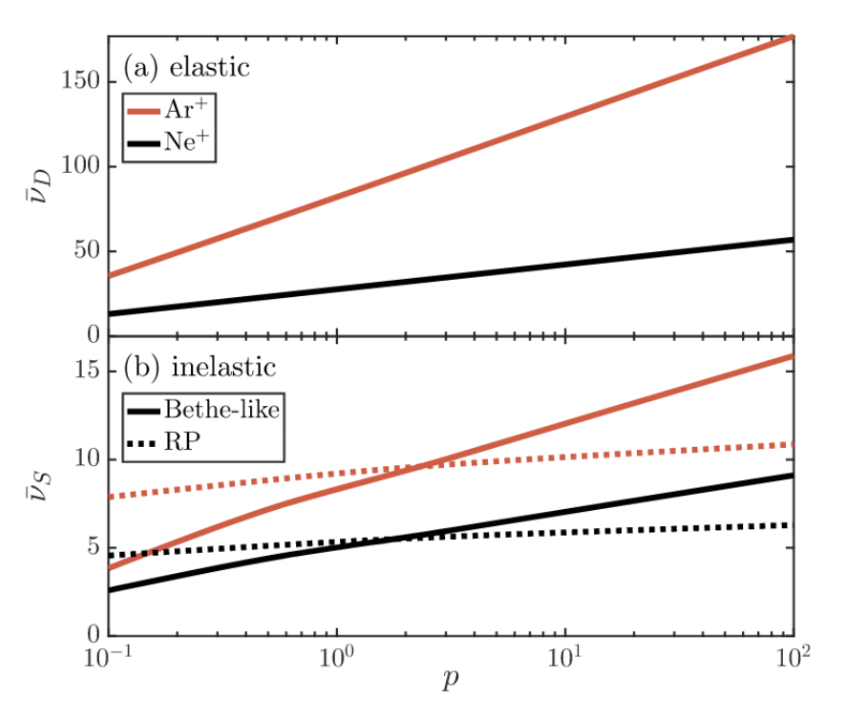

# Find pstar

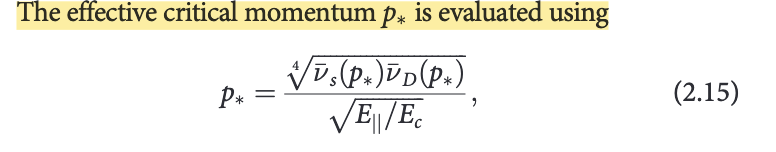

Here, $E_\parallel$ is the paralled electric field, $E_C$ is the Connor Hastie Field, $p_*$ is the (normalized) effective critical momentum

In [7]:
from scipy.optimize import fsolve

# Function to Solve
def fn(pstar,E_star,Z,Z0,nj,T, element):
    # T [eV]
    # Pstar = normalized momentum
    # Estar = Epar / E_CH (E_CH = Connor Hastie Critical Field)
    nuD, nuS = get_nuD_nuS(pstar,Z,Z0,nj,T,element)
    return pstar * (E_star)**(0.5) - (nuS * nuD)**(1/4)



pstar =  [1.12165907]


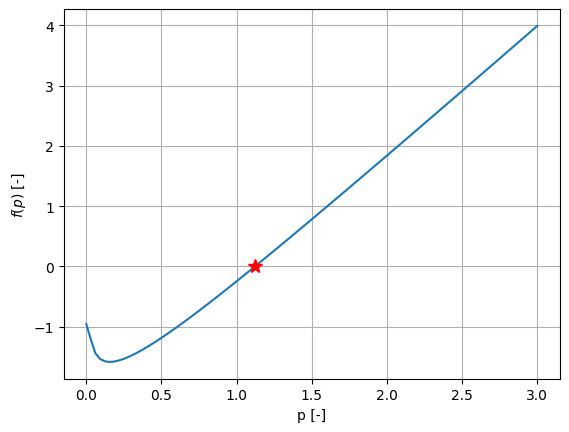

In [8]:
# Inputs
Z = np.array([1,10]); # Max. Ionization
Z0 = np.array([1,1]); # Ionization Level
nj = np.array([1e20,1e20]); # Density
T = 10;
E_star = 5

p = np.linspace(0,3,100)
y = fn(p,E_star,Z,Z0,nj,T, element='Ar')

plt.plot(p,y)
plt.xlabel('p [-]')
plt.ylabel('$f(p)$ [-]')
plt.grid()

# Solve the Equation to get pstar
out = fsolve(fn, 1, args=(E_star,Z,Z0,nj,T, 'Ar'))
print('pstar = ', out)

plt.plot(out,0,'r*',markersize=10)

<>:70: SyntaxWarning: invalid escape sequence '\,'
<>:70: SyntaxWarning: invalid escape sequence '\,'
C:\Users\grace\AppData\Local\Temp\ipykernel_42644\2583649373.py:70: SyntaxWarning: invalid escape sequence '\,'
  plt.title('$n_i, n_{Ne} = %1.3g, %1.3g,\, T = %1.1f \, eV$'%(nj[0],nj[1],T))


Text(0.5, 1.0, '$n_i, n_{Ne} = 1e+20, 1e+20,\\, T = 10.0 \\, eV$')

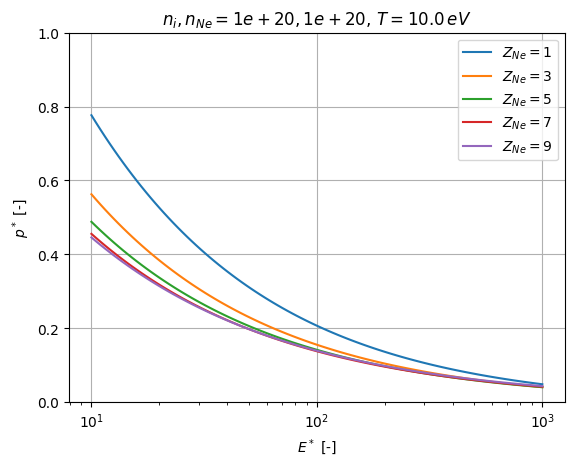

In [9]:
# Vary Estar

# Constants
Z = np.array([1,10]); # Max. Ionization
Z0 = np.array([1,1]); # Ionization Level
nj = np.array([1e20,1e20]); # Density
T = 10;

# Vary E_star
E_star = np.logspace(1,3,100)
pstar = np.zeros_like(E_star)

for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T,'Ne'))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')


# Now Try different Ne ionizations

Z0 = np.array([1,3]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T,'Ne'))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')

# Now Try different Ne ionizations

Z0 = np.array([1,5]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T,'Ne'))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')

# Now Try different Ne ionizations

Z0 = np.array([1,7]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T,'Ne'))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')

# Now Try different Ne ionizations

Z0 = np.array([1,9]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T,'Ne'))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')





plt.xlabel('$E^*$ [-]')
plt.ylabel('$p^*$ [-]')
plt.grid()
plt.xscale('log')
plt.legend()
plt.ylim([0,1])
plt.title('$n_i, n_{Ne} = %1.3g, %1.3g,\, T = %1.1f \, eV$'%(nj[0],nj[1],T))


<>:70: SyntaxWarning: invalid escape sequence '\,'
<>:70: SyntaxWarning: invalid escape sequence '\,'
C:\Users\grace\AppData\Local\Temp\ipykernel_42644\2966360300.py:70: SyntaxWarning: invalid escape sequence '\,'
  plt.title('$n_i, n_{Ar} = %1.3g, %1.3g,\, T = %1.1f \, eV$'%(nj[0],nj[1],T))


Text(0.5, 1.0, '$n_i, n_{Ar} = 1e+20, 1e+20,\\, T = 10.0 \\, eV$')

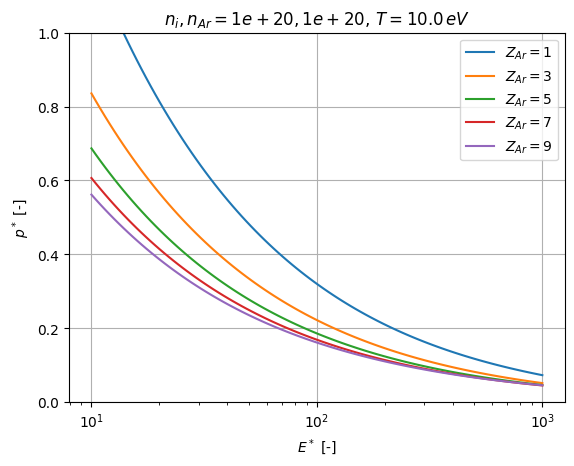

In [10]:
# Vary Estar for Ar

# Constants
Z = np.array([1,18]); # Max. Ionization
Z0 = np.array([1,1]); # Ionization Level
nj = np.array([1e20,1e20]); # Density
T = 10;

# Vary E_star
E_star = np.logspace(1,3,100)
pstar = np.zeros_like(E_star)

for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T,'Ar'))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ar} = ' + str(Z0[1]) + '$')


# Now Try different Ar ionizations

Z0 = np.array([1,3]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T,'Ar'))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ar} = ' + str(Z0[1]) + '$')

# Now Try different Ar ionizations

Z0 = np.array([1,5]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T,'Ar'))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ar} = ' + str(Z0[1]) + '$')

# Now Try different Ar ionizations

Z0 = np.array([1,7]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T,'Ar'))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ar} = ' + str(Z0[1]) + '$')

# Now Try different Ar ionizations

Z0 = np.array([1,9]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T,'Ar'))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ar} = ' + str(Z0[1]) + '$')





plt.xlabel('$E^*$ [-]')
plt.ylabel('$p^*$ [-]')
plt.grid()
plt.xscale('log')
plt.legend()
plt.ylim([0,1])
plt.title('$n_i, n_{Ar} = %1.3g, %1.3g,\, T = %1.1f \, eV$'%(nj[0],nj[1],T))
